# ۰۹ - بررسی ارتباط تأخیر در تحویل و رضایت مشتری

پاسخ به سؤال‌های بخش ۱۱ صورت‌مسئله: مقایسه گروه‌های تحویل، شدت تأخیر و کفایت نمونه.

## ۲. سؤال‌های کسب‌وکاری

1. میانگین امتیاز سفارش‌های به‌موقع و دیرکرددار چقدر است؟
2. اختلاف دو گروه چقدر است و آیا نمونه کافی است؟
3. با افزایش شدت تأخیر امتیاز چگونه تغییر می‌کند؟
4. آیا این الگو در همه دسته‌بندی‌ها دیده می‌شود؟
5. آیا می‌توان نتیجه گرفت تأخیر علت کاهش رضایت است؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های بخش ۱۱ صورت‌مسئله: مقایسه گروه‌های تحویل، شدت تأخیر و کفایت نمونه.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

سفارش‌های تحویل‌شده دارای امتیاز به دو گروه «به‌موقع یا زودتر» و «دیرکرددار» تقسیم می‌شوند. برای جلوگیری از شمارش مکرر، هر سفارش فقط یک امتیاز دارد. گروه «به‌موقع یا زودتر» شامل سفارش‌های زودتر از موعد و دقیقاً سر موعد است.

## ۶. تحلیل عددی

### ۱۱.۱ و ۱۱.۲ مقایسه دو گروه

In [2]:
display(M.delay_satisfaction_comparison(ds))

,group,n_orders,mean_score,pct_5,pct_1_or_2,n_1_or_2,pct_of_orders
0,on_time_or_early,89443,4.29,62.2665,9.2674,8289,93.3409
1,late,6381,2.27,16.5335,62.4197,3983,6.6591


In [3]:
display(pd.Series(M.delay_satisfaction_difference(ds), name="value"))

n_on_time_or_early             89443
n_late                          6381
mean_score_on_time_or_early     4.29
mean_score_late                 2.27
score_gap                       2.02
min_sample_reached              True
late_orders_at_risk             6381
Name: value, dtype: object

### ۱۱.۳ تا ۱۱.۵ شدت تأخیر و امتیاز

In [4]:
display(M.delay_bucket_satisfaction(ds))

,delay_bucket,n_orders,mean_score,median_score,pct_1_or_2,pct_5,label
0,on_time_or_early,89443,4.29,5.0,9.2674,62.2665,on time or early
1,1_3_days,1852,3.29,4.0,32.1274,33.1533,1-3 days late
2,4_7_days,1748,2.10,1.0,67.6773,14.0732,4-7 days late
3,more_than_7_days,2781,1.70,1.0,79.2880,7.0119,more than 7 days late


### ۱۱.۶ مقایسه در دسته‌بندی‌های دارای حجم کافی

In [5]:
display(M.category_delay_satisfaction(ds))

,category_label,total_orders,size_on_time_or_early,size_late,mean_on_time_or_early,mean_late,score_gap
0,musical_instruments,605.0,559.0,46.0,4.43,1.91,2.51
1,audio,345.0,305.0,40.0,4.12,1.72,2.39
2,toys,3774.0,3542.0,232.0,4.37,2.13,2.25
3,sports_leisure,7486.0,6999.0,487.0,4.37,2.17,2.20
4,baby,2787.0,2567.0,220.0,4.28,2.09,2.19
5,fashion_bags_accessories,1812.0,1711.0,101.0,4.36,2.19,2.17
6,pet_shop,1680.0,1596.0,84.0,4.38,2.25,2.13
7,stationery,2251.0,2105.0,146.0,4.43,2.32,2.12


## ۷. نمودارها

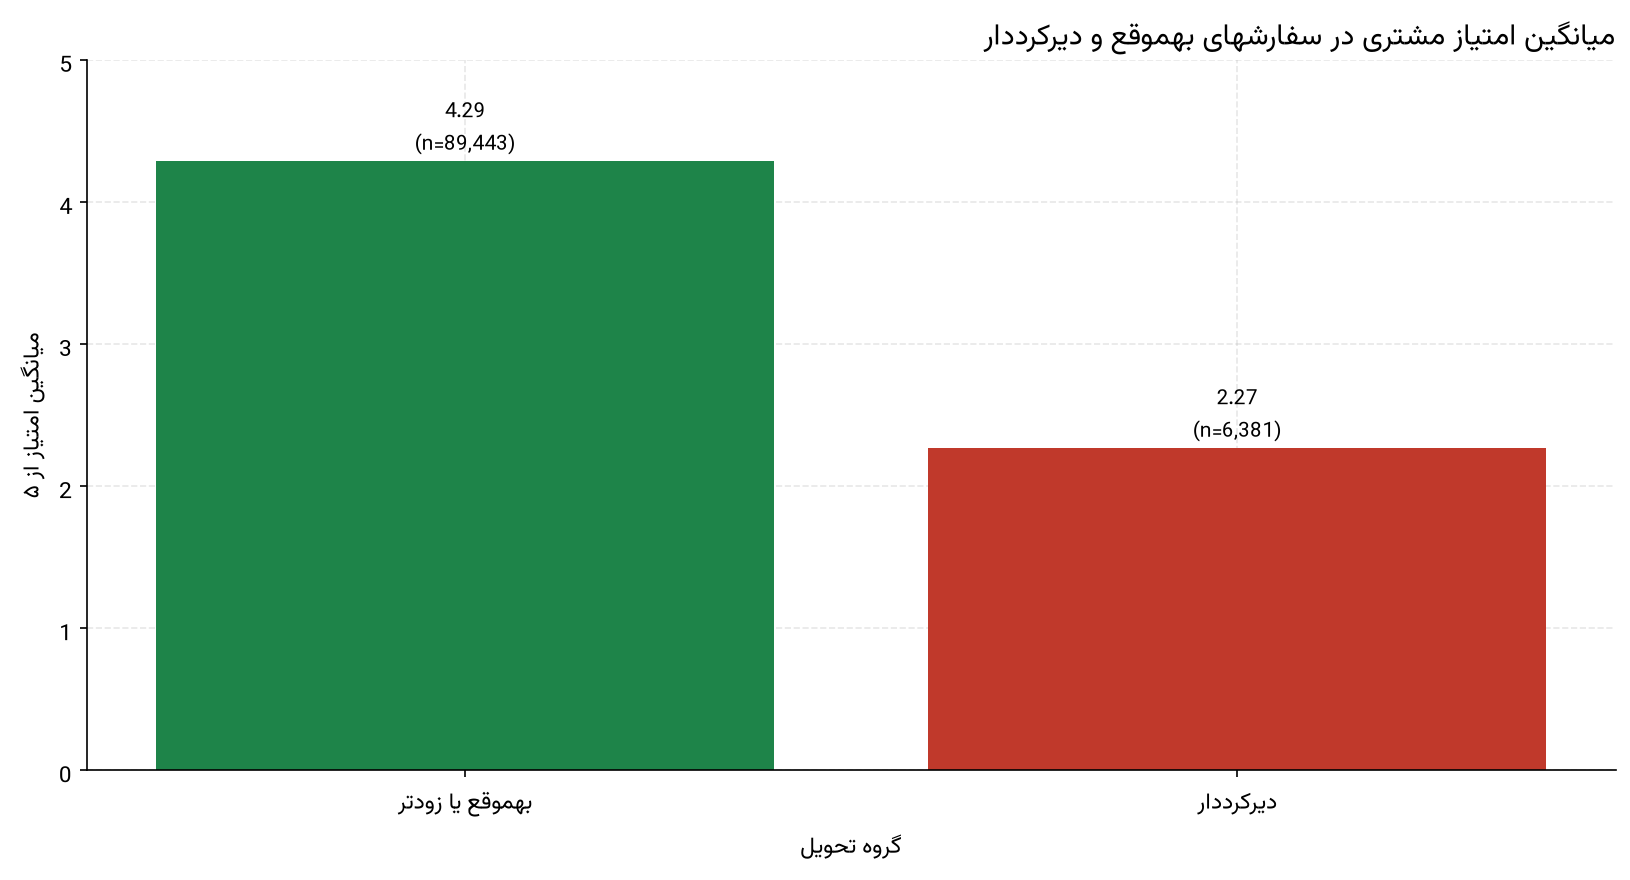

نمودار ۲۲ - اختلاف میانگین امتیاز دو گروه تحویل


In [6]:
display(Image(filename=str(FIGURES_DIR / "fig_22_delay_satisfaction.png"), width=920))
caption = FIGURES_DIR / "fig_22_delay_satisfaction.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

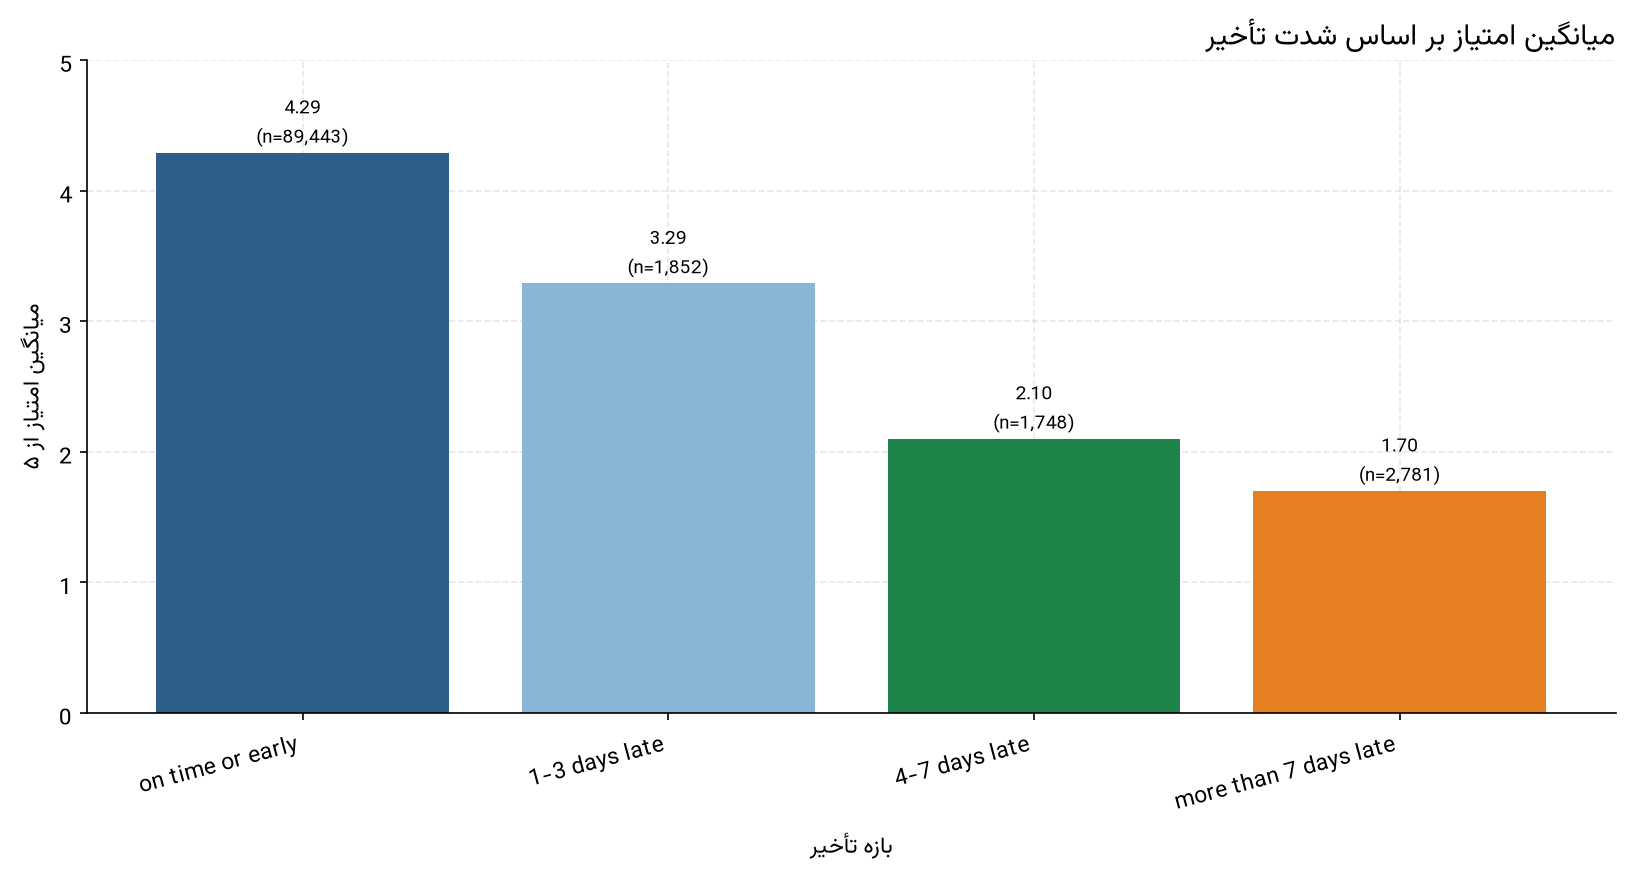

نمودار ۲۳ - هرچه تأخیر شدیدتر، میانگین امتیاز پایینتر


In [7]:
display(Image(filename=str(FIGURES_DIR / "fig_23_delay_bucket_satisfaction.png"), width=920))
caption = FIGURES_DIR / "fig_23_delay_bucket_satisfaction.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- گروه به‌موقع یا زودتر ۸۹٬۴۴۳ سفارش با میانگین امتیاز ۴.۲۹ و گروه دیرکرددار ۶٬۳۸۱ سفارش با میانگین امتیاز ۲.۲۷ دارد.
- اختلاف میانگین امتیاز دو گروه ۲.۰۲ امتیاز از ۵ است؛ اندازه‌ای بسیار بزرگ در مقیاس ۱ تا ۵.
- ۶۲.۴۲ درصد سفارش‌های دیرکرددار امتیاز ۱ یا ۲ داده‌اند، در برابر ۹.۲۷ درصد در گروه به‌موقع.
- با افزایش شدت تأخیر امتیاز پیوسته افت می‌کند: ۳.۲۹ برای ۱ تا ۳ روز، ۲.۱۰ برای ۴ تا ۷ روز و ۱.۷۰ برای بیش از ۷ روز تأخیر.
- در بیش از ۷ روز تأخیر، ۷۹.۲۹ درصد نظرات امتیاز ۱ یا ۲ هستند.
- این الگو در همه دسته‌بندی‌های بزرگ تکرار می‌شود؛ اختلاف امتیاز در `musical_instruments` ۲.۵۱ و در `stationery` ۲.۱۲ است.

## ۹. تفسیر کسب‌وکاری

تأخیر تحویل قوی‌ترین عاملی است که در این دیتاست با افت رضایت همراه است. اثر آن هم از نظر بزرگی اختلاف و هم از نظر پایداری در دسته‌بندی‌های مختلف چشمگیر است؛ به همین دلیل کاهش تأخیر کم‌هزینه‌ترین مسیر بهبود میانگین امتیاز محسوب می‌شود.

## ۱۰. محدودیت‌های تحلیل

این یک رابطه مشاهده‌شده است و اثبات علّیت نیست. ممکن است تأخیر و امتیاز پایین هر دو ناشی از عوامل مشترکی مانند ناموجود بودن کالا، مشکل فروشنده یا انتظار اولیه متفاوت مشتری باشند. برای استنباط علّی به آزمایش کنترل‌شده یا داده علت تأخیر نیاز است. همچنین ۶۴۶ سفارش تحویل‌شده نظر ثبت‌نشده دارند و در این تحلیل نیستند.

## ۱۱. نتیجه‌گیری

سفارش‌های دیرکرددار اقلیت کوچکی هستند (۶.۷۷ درصد) اما بخش بزرگی از نارضایتی را تولید می‌کنند؛ کاهش تأخیر بیشترین اثر را بر میانگین امتیاز دارد.